## 4. Apprentissage d'un CNN sur le dataset Fashion-MNIST

***Objectif**: Apprendre à classifier les images de vétements (10 categories) à l'aide d'un réseau de reurones convolutif (CNN)*

##### Etape 1: Importer les libraires

In [1]:
#importing libraries from libs.py

from libs import *        # np, pd, plt, tf, keras, layers, train_test_split, ...

#### Étape 2 — Charger le datasets

In [2]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()
print(x_train.shape, y_train.shape)

(60000, 28, 28) (60000,)


##### Etape 3: Visualiser les 5 premières lignes

In [3]:
# flatten each 28x28 image into 784 pixel columns
df_train = pd.DataFrame(x_train.reshape(len(x_train), -1),
                        columns=[f"pixel{i}" for i in range(784)])
df_train["label"] = y_train

df_test = pd.DataFrame(x_test.reshape(len(x_test), -1),
                       columns=[f"pixel{i}" for i in range(784)])
df_test["label"] = y_test

print(df_train.shape)   # (60000, 785)
df_train.head(5)

(60000, 785)


,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,label
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,9
1,0,0,0,0,0,1,0,0,0,0,...,114,130,76,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,22,...,0,1,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,33,96,...,0,0,0,0,0,0,0,0,0,3
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


##### Etape 4: Split train/test
```
On sépare avant tout calcul de statistiques. L'option stratify = y garde les 10 classes à égalité dans les deux jeux
```

In [4]:
# "classe" n'existe pas dans ce DataFrame : on utilise la colonne "column"
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
df_train["label_name"] = df_train["label"].map(dict(enumerate(class_names)))
print(df_train["label_name"].unique())

<StringArray>
[ 'Ankle boot', 'T-shirt/top',       'Dress',    'Pullover',     'Sneaker',
      'Sandal',     'Trouser',       'Shirt',        'Coat',         'Bag']
Length: 10, dtype: str


##### Regarder ce que « voit en classe» le réseau

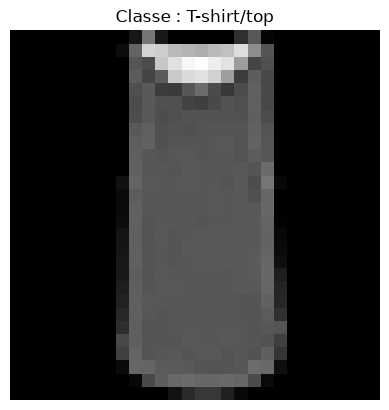

Pixel (17, 19) : 255
Pixel (17, 18) : 255
Pixel (18, 15) : 255
Pixel (14, 25) : 255
Pixel (16, 22) : 250
Pixel (19, 8) : 249
Pixel (16, 23) : 248
Pixel (17, 26) : 246
Pixel (17, 19) : 255
Pixel (17, 18) : 255
Pixel (18, 15) : 255
Pixel (14, 25) : 255
Pixel (16, 22) : 250
Pixel (19, 8) : 249
Pixel (16, 23) : 248
Pixel (17, 26) : 246
Pixel (17, 19) : 255
Pixel (17, 18) : 255
Pixel (18, 15) : 255
Pixel (14, 25) : 255
Pixel (16, 22) : 250
Pixel (19, 8) : 249
Pixel (16, 23) : 248
Pixel (17, 26) : 246
Pixel (17, 19) : 255
Pixel (17, 18) : 255
Pixel (18, 15) : 255
Pixel (14, 25) : 255
Pixel (16, 22) : 250
Pixel (19, 8) : 249
Pixel (16, 23) : 248
Pixel (17, 26) : 246
Pixel (17, 19) : 255
Pixel (17, 18) : 255
Pixel (18, 15) : 255
Pixel (14, 25) : 255
Pixel (16, 22) : 250
Pixel (19, 8) : 249
Pixel (16, 23) : 248
Pixel (17, 26) : 246
Pixel (17, 19) : 255
Pixel (17, 18) : 255
Pixel (18, 15) : 255
Pixel (14, 25) : 255
Pixel (16, 22) : 250
Pixel (19, 8) : 249
Pixel (16, 23) : 248
Pixel (17, 26) : 24

In [5]:
i = 2               # index[2]=Dress   
plt.imshow(x_train[i], cmap="gray")
plt.title(f"Classe : {class_names[int(y_train[i])]}")
plt.axis("off")
plt.show()
poids = x_train[2]                                             
positions = np.argsort(poids)                  
meilleures = positions[-8:]                     
for i in meilleures:                            
    pixels = x_train[0].ravel()
    meilleures = np.argsort(pixels)[-8:][::-1]

    for index in meilleures:
        ligne, colonne = divmod(int(index), 28)
        print(f"Pixel ({ligne}, {colonne}) : {int(pixels[index])}")

In [6]:
# split train/test
df_train["split"] = "train"
df_test["split"] = "test"
df = pd.concat([df_train, df_test], ignore_index=True)

##### Etape 5: One-Hot Encoding pour les sorties

In [7]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(sparse_output=False)
y_train = encoder.fit_transform(y_train.reshape(-1, 1))
y_test = encoder.transform(y_test.reshape(-1, 1))
print("Sortie encodées :\n", y_train[:5])

Sortie encodées :
 [[0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
 [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]


##### Etape 6: Normaliser les features (standardisation)

```
Le scaler est ajusté sur le train uniquement : les test est seulement transformé
```

In [8]:
from tensorflow import keras
from tensorflow.keras import layers

models = keras.models
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

# scale pixels to 0-1 and add the channel dimension: (60000, 28, 28) -> (60000, 28, 28, 1)
x_test = np.asarray(x_test, dtype=np.float32)
if x_test.max() > 1.0:          # not normalized yet
    x_test = x_test / 255.0
x_test = x_test.reshape(-1, 28, 28, 1)

##### Etape 7: Construire le modèle MLP

In [9]:
model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax"),   # 10 clothing classes
])

model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",   # labels are integers 0-9
              metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

#### Réseau de neurones 

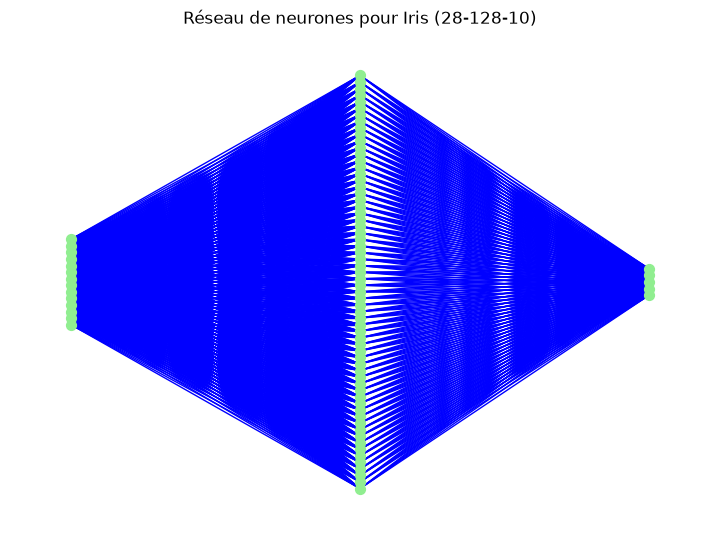

In [10]:
import networkx as nx

layers = [14, 64, 5]

G = nx.DiGraph()
pos = {}
layer_positions = []

for l, n_neurons in enumerate(layers):
    layer_pos = []
    offset = (n_neurons - 1) / 2              # centre each layer vertically
    for i in range(n_neurons):
        node_id = f"L{l}N{i}"
        G.add_node(node_id, layer=l)
        pos[node_id] = (l, offset - i)        # neurons in columns
        layer_pos.append(node_id)
    layer_positions.append(layer_pos)         # <-- fix: node names, not `layers`

for l in range(len(layers) - 1):
    for src in layer_positions[l]:
        for dst in layer_positions[l + 1]:
            G.add_edge(src, dst)

plt.figure(figsize=(7, 5))
nx.draw(G, pos, with_labels=False, node_size=50,
        node_color="lightgreen", edge_color="blue", arrows=False)
plt.title("Réseau de neurones pour Iris (28-128-10)", fontsize=12)
plt.show()

#### Etape 8: Compiler et Entraîner le modèle

In [11]:
# Parametètres: optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    x_train, y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 14s 16ms/step - accuracy: 0.7470 - loss: 0.9378 - val_accuracy: 0.8437 - val_loss: 0.4140
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 0.8336 - loss: 0.4642 - val_accuracy: 0.8691 - val_loss: 0.3533
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 0.8523 - loss: 0.4035 - val_accuracy: 0.8758 - val_loss: 0.3333
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 0.8641 - loss: 0.3635 - val_accuracy: 0.8828 - val_loss: 0.3181
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 0.8713 - loss: 0.3479 - val_accuracy: 0.8890 - val_loss: 0.3050
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 0.8790 - loss: 0.3244 - val_accuracy: 0.8905 - val_loss: 0.3003
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.8846 - loss: 0.3130 - val_accuracy: 0.8873 - val_loss: 0.3149
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 21s 16ms/step - accuracy: 0.8887 - loss: 0.3005 - 

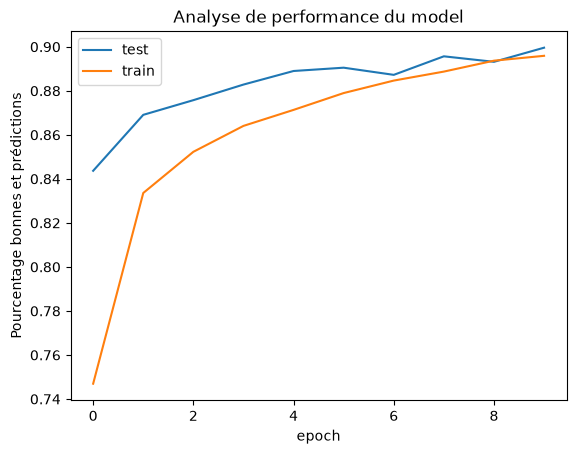

In [12]:
# Analyse de performance du model en graph
plt.plot(history.history["val_accuracy"])
plt.plot(history.history["accuracy"])
plt.title("Analyse de performance du model")
plt.xlabel("epoch")
plt.ylabel("Pourcentage bonnes et prédictions")
plt.legend(["test", "train"])

##### La fonction d'erreur est croissante sur les epoch

In [13]:
loss, acc=model.evaluate(x_test, y_test, verbose=2)
print(f"\nPrécision sur le test: {acc*100:.2f}")

313/313 - 2s - 6ms/step - accuracy: 0.1511 - loss: 5.0541

Précision sur le test: 15.11


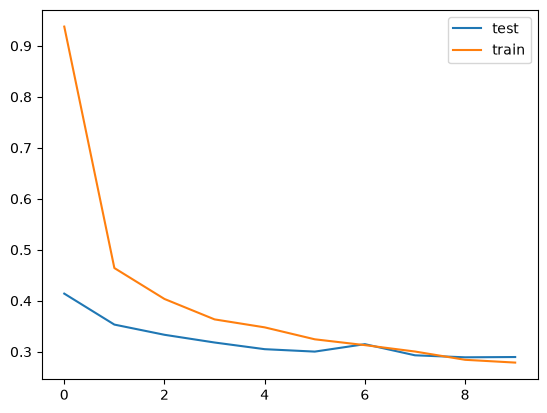

In [14]:
plt.plot(history.history["val_loss"])
plt.plot(history.history["loss"])
plt.legend(["test", "train"])

##### Etape 9: Visualiser la prédiction pour quelques exemples

In [15]:
# x_test is already normalized and shaped (N, 28, 28, 1)
predictions = model.predict(x_test, batch_size=256)   # shape (10000, 10), probabilities
pred_classes = np.argmax(predictions, axis=1)

print("Predictions (first 3):\n", predictions[:3].round(3))
print("Classes prédites :", pred_classes[:20])
print("Vraies classes   :", y_test[:20])
print("Accuracy :", (pred_classes == y_test).mean())

40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step
Predictions (first 3):
 [[0.    0.    0.    0.    0.    0.108 0.    0.428 0.    0.464]
 [0.004 0.001 0.    0.027 0.    0.171 0.002 0.361 0.021 0.411]
 [0.    0.    0.    0.007 0.    0.226 0.    0.172 0.003 0.593]]
Classes prédites : [9 9 9 9 9 9 9 9 9 9 9 9 7 9 9 9 9 9 7 9]
Vraies classes   : [9 2 1 1 6 1 4 6 5 7 4 5 7 3 4 1 2 4 8 0]
Accuracy : 0.1511


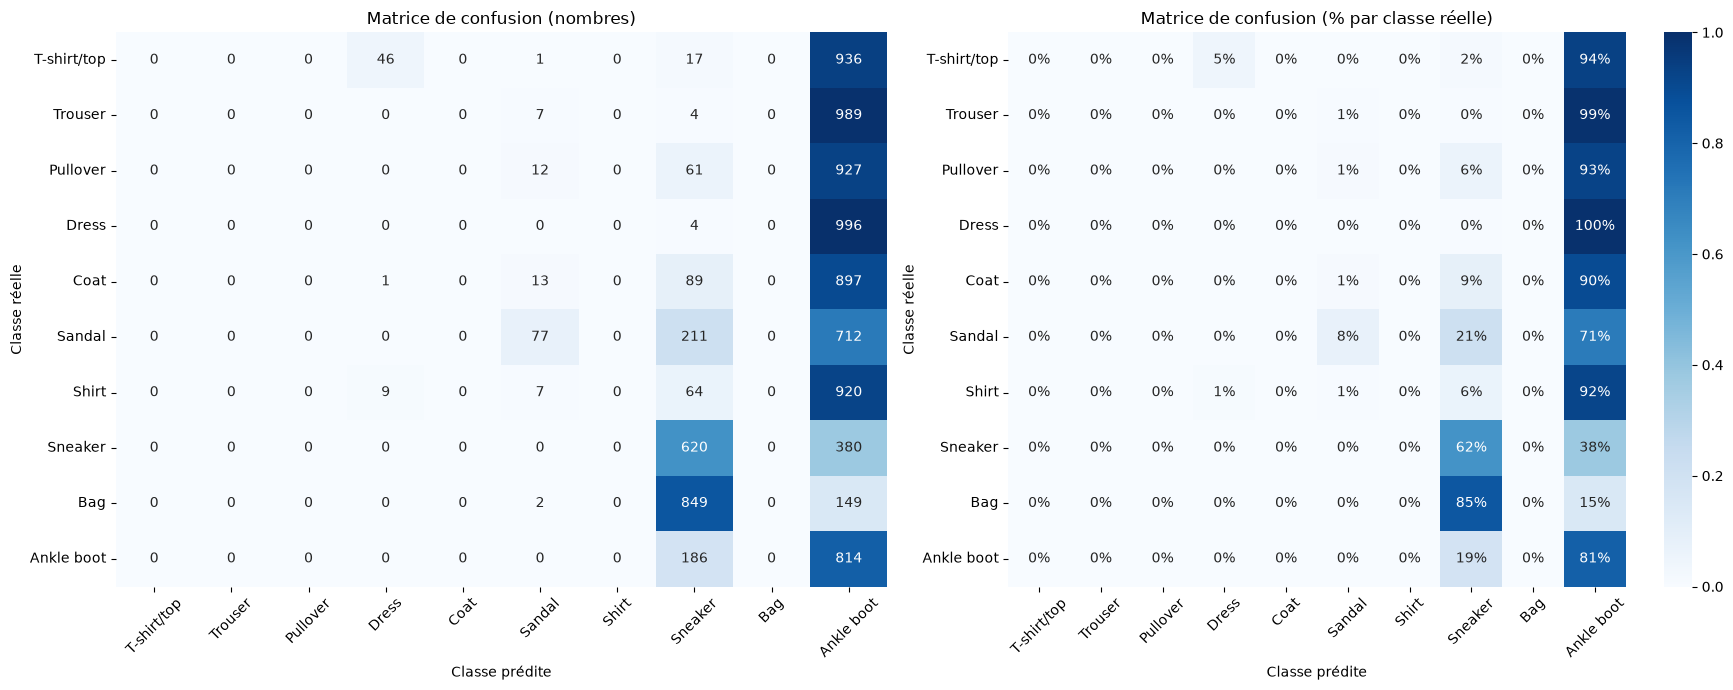

In [16]:
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

y_pred = np.argmax(model.predict(x_test, verbose=0), axis=1)
cm = confusion_matrix(y_test, y_pred)

# Normalized by row: each cell = share of the real class predicted as each class
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=class_names, yticklabels=class_names, cbar=False)
axes[0].set_title("Matrice de confusion (nombres)")

sns.heatmap(cm_norm, annot=True, fmt=".0%", cmap="Blues", ax=axes[1],
            xticklabels=class_names, yticklabels=class_names, vmin=0, vmax=1)
axes[1].set_title("Matrice de confusion (% par classe réelle)")

for ax in axes:
    ax.set_xlabel("Classe prédite")
    ax.set_ylabel("Classe réelle")
    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()

In [17]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred, zero_division=0))

              precision    recall  f1-score   support

           0       0.00      0.00      0.00      1000
           1       0.00      0.00      0.00      1000
           2       0.00      0.00      0.00      1000
           3       0.00      0.00      0.00      1000
           4       0.00      0.00      0.00      1000
           5       0.65      0.08      0.14      1000
           6       0.00      0.00      0.00      1000
           7       0.29      0.62      0.40      1000
           8       0.00      0.00      0.00      1000
           9       0.11      0.81      0.19      1000

    accuracy                           0.15     10000
   macro avg       0.10      0.15      0.07     10000
weighted avg       0.10      0.15      0.07     10000



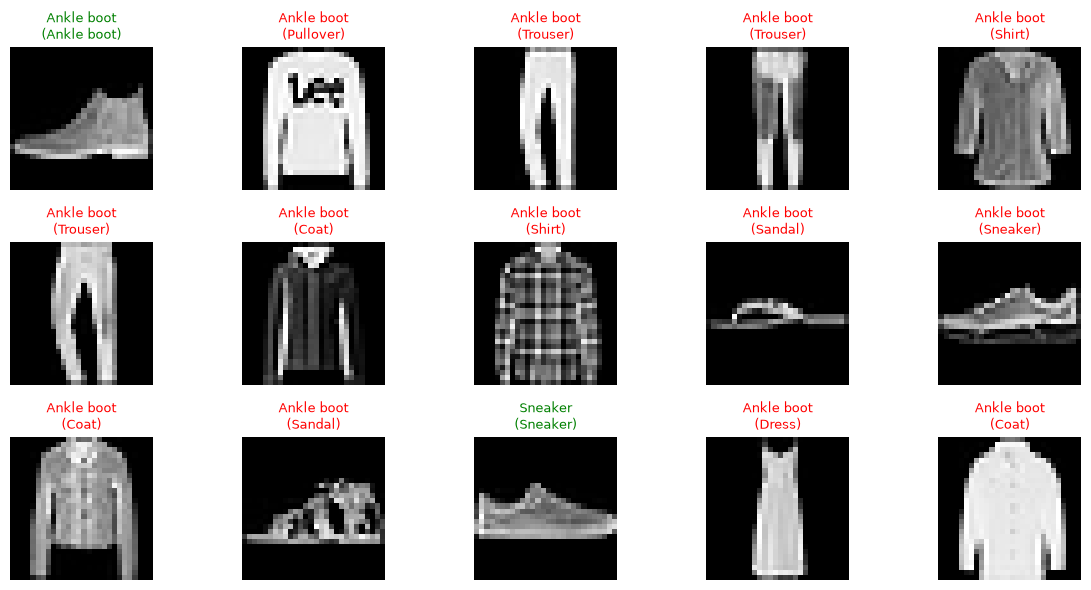

In [18]:
# Plotting predictions

plt.figure(figsize=(12, 6))
for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    ok = pred_classes[i] == y_test[i]
    plt.title(f"{class_names[pred_classes[i]]}\n({class_names[y_test[i]]})",
              color="green" if ok else "red", fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()